# TRIGRS tutorial adapted to slope units

This example adapts **Appendix 2 of Baum, Savage, and Godt (2008)** to independent `unsatstab` columns over nine slope units (SUs). The source is the 100-cell tutorial grid distributed with [USGS Open-File Report 2008–1159](https://pubs.usgs.gov/of/2008/1159/). Mean geometry and majority material assignments are read directly from `SU_tutorial.gpkg`; rainfall and mechanical properties follow the reference initialization table.

The model uses the default `srivastava_yeh` formulation and storage-based water-table reconstruction. The reference tutorial selects saturated infiltration and routes runoff between cells. Consequently, this SU example reproduces the supported input scenario, rather than the original pressure and failure maps.

## Reference inputs and SU adaptation

| Input | TRIGRS tutorial | This example |
| --- | --- | --- |
| Spatial domain | 10 × 10 cells, 10 m resolution | Same extent, aggregated into 9 SUs |
| Slope and soil depth | `slope.asc`, `zmax.asc` | Cell-centre means; all 9 match the GeoPackage |
| Initial water table | `depthwt.asc`, including the spring cell at zero depth | `zw_mean` from the GeoPackage, unchanged; spring effects are excluded |
| Material assignment | `zones.asc` | Majority zone per SU; 2 minority-zone cells in SU 2 receive its majority material |
| Rainfall | 3 × 10⁻⁷ and 9 × 10⁻⁵ m/s over 48 h and 12 h | Same: 1.08 and 324 mm/h |
| Background flux | 2 × 10⁻⁸ m/s, except −2 × 10⁻⁸ m/s at the spring | Uniform 2 × 10⁻⁸ m/s; no spring discharge or spring-derived correction |
| Strength, soil/water unit weights, conductivity, water-content limits | Initialization table 2-2 | Same values |
| Hydraulic formulation | Negative `Alpha` selects saturated infiltration; diffusivity is used | Positive Gardner parameters 0.5 and 8 m⁻¹; saturated diffusivity is not used |
| Drainage and runoff | Saturated-flow solution and cell-to-cell runoff routing | Declared basal drainage efficiency 0.1; no runoff routing |

Rainfall follows **table 2-2 and the distributed `tr_in.txt`**. The appendix narrative also gives different intensities and a 28-hour storm description; those do not match this initialization. The audit and source checksums are in `research/trigrs-tutorial-reference/`.


## Read mean SU geometry and map column names

`SU_tutorial.gpkg` supplies polygons, mean slope (`slope_mean`), mean soil depth (`zmax_mean`), mean initial water-table depth (`zw_mean`), and majority material (`geo_majority`). Use these stored values directly for every SU, without recalculating or substituting means from the reference grids. Median and elevation fields remain source attributes.

Create unique `su_id` values in layer order, then use [column mapping](/unsatstab/inputs-outputs/#column-names-from-gis-files) to associate these attributes with solver fields. Spring effects are excluded from the initial conditions and background flux.

In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import tol_colors as tc
import numpy as np
import pandas as pd
from IPython.display import display
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "unsatstab").is_dir())
slope_units = us.read_slope_units(ROOT / "docs" / "tutorials" / "data" / "SU_tutorial.gpkg", layer="SU_tutorial")
required_source_fields = ["slope_mean", "zmax_mean", "zw_mean", "geo_majority"]
missing = set(required_source_fields) - set(slope_units.columns)
if missing:
    raise KeyError(f"Missing source fields: {sorted(missing)}")
if slope_units[required_source_fields].isna().any().any():
    raise ValueError("Geometry means and geo_majority must be present in every record.")
if not slope_units["geo_majority"].isin([1, 2]).all():
    raise ValueError("geo_majority must select material 1 or 2.")
slope_units["su_id"] = np.arange(1, len(slope_units) + 1)
column_mapping = {
    "material_id": "geo_majority", "slope_angle_deg": "slope_mean",
    "maximum_depth_m": "zmax_mean",
    "initial_water_table_depth_m": "zw_mean",
}
print(f"Package version: {us.__version__}")
print(f"Slope units: {len(slope_units)}; CRS: {slope_units.crs.name}")
display(slope_units.drop(columns="geometry"))

Package version: 1.0.0
Slope units: 9; CRS: WGS 84 / UTM zone 18N


,id,zmax_mean,zmax_median,zw_mean,zw_median,elev_mean,elev_median,elev_min,elev_max,slope_mean,slope_median,geo_majority,su_id
0,1,1.950000,2.0,1.483333,1.5,81.500000,83.5,68.0,92.0,25.766667,26.60,2.0,1
1,1,2.000000,2.0,1.500000,1.5,98.150000,98.0,93.0,103.0,19.285000,19.50,1.0,2
2,1,2.000000,2.0,1.500000,1.5,71.800000,71.0,67.0,81.0,14.310000,16.70,2.0,3
3,1,1.936364,2.0,1.500000,1.5,87.272727,88.0,76.0,94.0,27.181818,26.60,2.0,4
4,1,1.887500,2.0,1.466667,1.5,75.166667,73.0,67.0,91.0,21.491667,24.20,2.0,5
5,1,1.877778,2.0,1.477778,1.5,84.444444,87.0,69.0,93.0,28.077778,29.50,2.0,6
6,1,1.965000,2.0,1.500000,1.5,72.300000,70.5,65.0,86.0,18.570000,19.85,2.0,7
7,1,2.000000,2.0,1.500000,1.5,70.857143,69.0,65.0,81.0,15.614286,16.70,2.0,8
8,1,2.000000,2.0,1.500000,1.5,69.555556,68.0,65.0,77.0,12.988889,12.00,2.0,9


## Define the two geozone materials

Cohesion, friction angle, unit weights, conductivity and water-content limits follow table 2-2. Water unit weight is 9800 N/m³. The SU table supplies slope, soil depth and initial water-table depth without changes. Both materials use a uniform background flux of 2 × 10⁻⁸ m/s, excluding the reference spring and any spring-derived adjustment.

The source uses `Alpha=-0.5` and `-8` as switches to the saturated TRIGRS solution, with diffusivities 6 × 10⁻⁶ and 8 × 10⁻⁴ m²/s. `unsatstab` uses positive Gardner parameters 0.5 and 8 m⁻¹ and does not solve that saturated diffusion problem. These values therefore define an explicit unsaturated adaptation.

Finite basal drainage efficiency 0.1 is an `unsatstab` assumption, not a parameter supplied by the TRIGRS tutorial. Its capacity follows [basal transfer and drainage](/unsatstab/fundamentals/#basal-transfer-and-drainage-capacity).

In [ ]:
materials = {
    1: {
        "hydro": us.HydraulicProperties(
            saturated_hydraulic_conductivity=1.0e-7,
            alpha=0.5,
            theta_s=0.45,
            theta_r=0.05,
            long_term_infiltration=2.0e-8,
            equation_set="srivastava_yeh",
            n_roots=120,
            n_depths=80,
        ),
        "strength": us.StrengthProperties(
            cohesion=3.5e3,
            friction_angle_deg=35.0,
            unit_weight_soil=22.0e3,
            unit_weight_water=9.8e3,
        ),
        "boundary": us.FinitePerchedBoundary(drainage_efficiency=0.1),
    },
    2: {
        "hydro": us.HydraulicProperties(
            saturated_hydraulic_conductivity=1.0e-4,
            alpha=8.0,
            theta_s=0.45,
            theta_r=0.06,
            long_term_infiltration=2.0e-8,
            equation_set="srivastava_yeh",
            n_roots=120,
            n_depths=80,
        ),
        "strength": us.StrengthProperties(
            cohesion=8.0e3,
            friction_angle_deg=31.0,
            unit_weight_soil=22.0e3,
            unit_weight_water=9.8e3,
        ),
        "boundary": us.FinitePerchedBoundary(drainage_efficiency=0.1),
    },
}
material_rows = []
for material_id, material in materials.items():
    h, s = material["hydro"], material["strength"]
    material_rows.append({
        "Geozone": material_id,
        "Units": int((slope_units["geo_majority"] == material_id).sum()),
        "Cohesion [Pa]": s.cohesion, "Friction angle [deg]": s.friction_angle_deg,
        "Soil unit weight [N/m³]": s.unit_weight_soil,
        "Saturated conductivity [mm/h]": h.saturated_hydraulic_conductivity * 3.6e6,  # convert m/s to mm/h
        "Gardner parameter [1/m]": h.alpha,
        "Saturated water content [-]": h.theta_s, "Residual water content [-]": h.theta_r,
    })
display(pd.DataFrame(material_rows))

,Geozone,Units,Cohesion [Pa],Friction angle [deg],Soil unit weight [N/m³],Saturated conductivity [mm/h],Gardner parameter [1/m],Saturated water content [-],Residual water content [-]
0,1,1,3500.0,35.0,22000.0,0.36,0.5,0.45,0.05
1,2,8,8000.0,31.0,22000.0,360.00,8.0,0.45,0.06


## Apply rainfall and distinguish admitted water

The supplied time vector `[0, 48, 60]` contains **breakpoints**, not successive durations: the two intervals last 48 and 12 hours. Their intensities are 1.08 and 324 mm/h, giving 3939.84 mm of gross rainfall.

Each unit caps infiltration at its material's saturated conductivity. Geozone 1 admits 0.36 mm/h throughout, for 21.6 mm in 60 hours. Geozone 2 admits both rainfall rates, for 3939.84 mm. The remaining rain is discarded; it is not ponded or routed to other units. This difference must be considered when interpreting the geozone responses.

Maps are requested at 0, 24, 48, 52, 56 and 60 hours. At 48 hours the instantaneous rainfall changes to 324 mm/h, while the subsurface state reflects the preceding history. At 60 hours the rain stops; the column response can continue afterward. Storage integration uses steps no longer than five minutes.

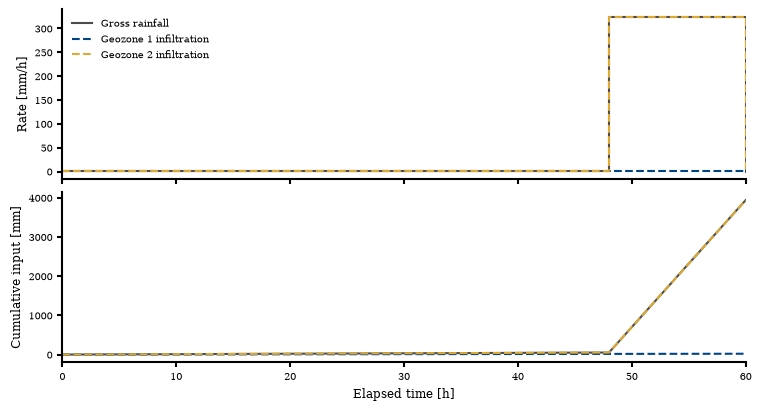

,Geozone,Rainfall [mm],Effective infiltration [mm],Rejected rainfall [mm]
0,1,3939.84,21.60,3918.24
1,2,3939.84,3939.84,0.00


In [3]:
rainfall = us.RainfallSeries(
    breakpoints=np.array([0.0, 48.0, 60.0]),  # hours
    fluxes=np.array([1.08, 324.0]) / 3.6e6,  # convert mm/h to m/s
)
output_times = np.array([0.0, 24.0, 48.0, 52.0, 56.0, 60.0])  # hours
rates_mm_h = rainfall.fluxes * 3.6e6  # convert m/s to mm/h
interval_hours = np.diff(rainfall.breakpoints)
gross_mm = np.dot(interval_hours, rates_mm_h)
assert np.isclose(gross_mm, 3939.84)
input_rows = []
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7.5, 4.0), constrained_layout=True)
axes[0].step(rainfall.breakpoints, np.r_[rates_mm_h, 0.0], where="post", color="0.3", lw=1.5, label="Gross rainfall")
axes[1].plot(rainfall.breakpoints, np.r_[0.0, np.cumsum(interval_hours * rates_mm_h)], color="0.3", lw=1.5, label="Gross rainfall")
for material_id, color in zip(materials, [tc.colorsets["high_contrast"].blue, tc.colorsets["high_contrast"].yellow]):
    capacity_mm_h = materials[material_id]["hydro"].saturated_hydraulic_conductivity * 3.6e6  # convert m/s to mm/h
    admitted_rates = np.minimum(rates_mm_h, capacity_mm_h)
    admitted_mm = np.dot(interval_hours, admitted_rates)
    input_rows.append({"Geozone": material_id, "Rainfall [mm]": gross_mm,
                       "Effective infiltration [mm]": admitted_mm, "Rejected rainfall [mm]": gross_mm - admitted_mm})
    axes[0].step(rainfall.breakpoints, np.r_[admitted_rates, 0.0], where="post", color=color, ls="--", lw=1.5, label=f"Geozone {material_id} infiltration")
    axes[1].plot(rainfall.breakpoints, np.r_[0.0, np.cumsum(interval_hours * admitted_rates)], color=color, ls="--", lw=1.5)
axes[0].set_ylabel("Rate [mm/h]")
axes[0].legend()
axes[1].set(xlabel="Elapsed time [h]", ylabel="Cumulative input [mm]", xlim=(0.0, rainfall.duration))
plt.show()
display(pd.DataFrame(input_rows))

## Run full-column responses

The runner uses the stored `slope_mean`, `zmax_mean`, and `zw_mean` values, uniform background flux, and majority material properties. Without a separate observation plane, plane FS is extracted at the column base.

The summary reports minimum FS anywhere in each complete profile as well as base FS. The maps use the profile minimum, matching the type of stability output in the TRIGRS tutorial. Both are sampled at the six requested times. Series terms, depth sampling and storage intervals are [numerical controls](/unsatstab/inputs-outputs/#numerical-controls).

In [4]:
simulation = us.run_slope_units(
    slope_units, materials, rainfall=rainfall, output_times=output_times,
    column_mapping=column_mapping, n_jobs=2,
    storage_time_step=5.0 / 60.0,  # convert minutes to hours
)
summary = simulation.summary()
assert not summary["initial_water_table_depth_was_clamped"].any()
for unit_id, result in simulation.columns.items():
    assert result.metadata["equation_set"] == "srivastava_yeh"
    assert result.water_table_rise[0] == 0.0
    source = slope_units.loc[slope_units.su_id == unit_id].iloc[0]
    assert np.isclose(result.metadata["initial_water_table_depth_m"], source.zw_mean)
    assert result.arrays()["z"][-1] == slope_units.loc[slope_units.su_id == unit_id, "zmax_mean"].iloc[0]
display(summary[["su_id", "geo_majority", "minimum_factor_of_safety",
                 "minimum_factor_of_safety_at_failure_plane", "failure_plane_failed",
                 "maximum_water_table_rise_m"]].round(4))
state_rows = []
for index, time in enumerate(output_times):
    for material_id in materials:
        results = [simulation.result_for(unit_id) for unit_id in slope_units.loc[slope_units.geo_majority == material_id, "su_id"]]
        state_rows.append({
            "Time [h]": time, "Geozone": material_id,
            "Units with base FS <= 1": sum(r.factor_of_safety_at_failure_plane[index] <= 1.0 for r in results),
            "Units with any-depth FS <= 1": sum(np.min(r.arrays()["factor_of_safety"][index]) <= 1.0 for r in results),
            "Minimum base FS": min(r.factor_of_safety_at_failure_plane[index] for r in results),
            "Median water-table rise [m]": np.median([r.water_table_rise[index] for r in results]),
            "Water tables at surface": sum(np.isclose(r.water_table_depth[index], 0.0) for r in results),
        })
state_table = pd.DataFrame(state_rows)
display(state_table.round(4))

,su_id,geo_majority,minimum_factor_of_safety,minimum_factor_of_safety_at_failure_plane,failure_plane_failed,maximum_water_table_rise_m
0,1,2.0,1.1667,1.1667,0,1.4833
1,2,1.0,2.0780,2.0780,0,0.0000
2,3,2.0,2.0656,2.0656,0,1.5000
3,4,2.0,1.1111,1.1111,0,1.5000
4,5,2.0,1.4115,1.4115,0,1.4667
5,6,2.0,1.0910,1.0910,0,1.4778
6,7,2.0,1.6050,1.6050,0,1.5000
7,8,2.0,1.8938,1.8938,0,1.5000
8,9,2.0,2.2750,2.2750,0,1.5000


,Time [h],Geozone,Units with base FS <= 1,Units with any-depth FS <= 1,Minimum base FS,Median water-table rise [m],Water tables at surface
0,0.0,1,0,0,2.0780,0.0,0
1,0.0,2,0,0,1.4858,0.0,0
2,24.0,1,0,0,2.0780,0.0,0
3,24.0,2,0,0,1.4858,0.0,0
4,48.0,1,0,0,2.0780,0.0,0
5,48.0,2,0,0,1.4858,0.0,0
6,52.0,1,0,0,2.0780,0.0,0
7,52.0,2,0,0,1.0910,1.5,8
8,56.0,1,0,0,2.0780,0.0,0
9,56.0,2,0,0,1.0910,1.5,8


## Six spatial snapshots of minimum factor of safety

Each panel shows minimum FS over the full column at the selected time, corresponding to the stability output type used in the reference tutorial. All panels share a scale from 1 to 2; values below 1 are dark gray. Base FS remains available in the tables. Reaching FS ≤ 1 is a deterministic model threshold, rather than an observed landslide or failure probability.

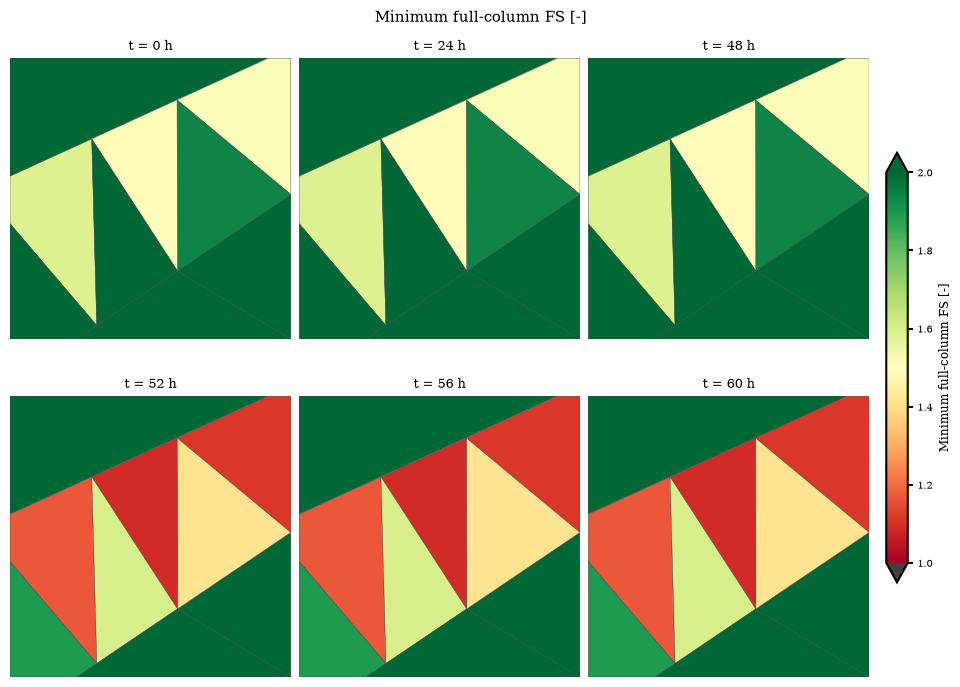

In [5]:
snapshots = {}
for index, time in enumerate(output_times):
    snapshots[("minimum_factor_of_safety", time)] = np.array([
        simulation.result_for(unit_id).arrays()["factor_of_safety"][index].min()
        for unit_id in slope_units["su_id"]
    ])
    snapshots[("water_table_rise", time)] = np.array([
        simulation.result_for(unit_id).water_table_rise[index]
        for unit_id in slope_units["su_id"]
    ])
fs_norm = Normalize(vmin=1.0, vmax=2.0)
fs_cmap = mpl.colormaps["RdYlGn"].copy()
fs_cmap.set_under("0.25")
all_rise = np.concatenate([snapshots[("water_table_rise", time)] for time in output_times])
rise_norm = Normalize(vmin=0.0, vmax=max(float(all_rise.max()), 1e-6))

def plot_snapshots(field, norm, cmap, label):
    fig, axes = plt.subplots(2, 3, figsize=(9.5, 7.0), constrained_layout=True)
    xmin, ymin, xmax, ymax = slope_units.total_bounds
    for ax, time in zip(axes.flat, output_times):
        frame = slope_units.copy()
        frame["snapshot_value"] = snapshots[(field, time)]
        frame.plot(column="snapshot_value", cmap=cmap, norm=norm, legend=False,
                   edgecolor="0.25", linewidth=0.3, ax=ax)
        ax.set_title(f"t = {time:g} h")
        ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax))
        ax.set_axis_off()
    fig.suptitle(label, fontsize=11)
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=list(axes.flat),
                 label=label, fraction=0.025, pad=0.02, shrink=0.85, extend="both")
    plt.show()

plot_snapshots("minimum_factor_of_safety", fs_norm, fs_cmap,
               "Minimum full-column FS [-]")

## Six spatial snapshots of water-table rise

Rise is measured above each unit's initial water table from the GeoPackage. Current depth is `zw_mean` minus rise. All six panels share a color scale. The reconstruction caps the water table at the surface; constant rise at that cap does not mean incoming water has stopped.

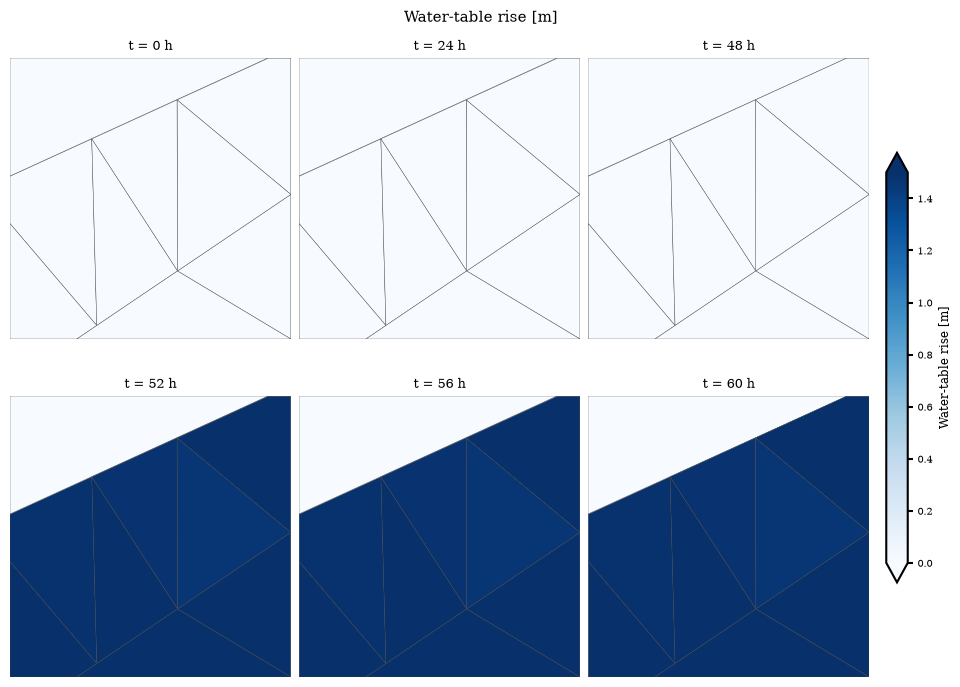

In [6]:
plot_snapshots("water_table_rise", rise_norm, "Blues",
               "Water-table rise [m]")

## Interpret the SU adaptation

Rainfall and strength parameters follow the reference inputs. Geometry and initial water-table depths use the unchanged GeoPackage means, and materials use its majority zones. Geozone 1 admits only its 0.36 mm/h conductivity cap, whereas geozone 2 admits both rainfall rates. TRIGRS redistributes runoff and includes a spring; this adaptation excludes spring effects and treats SUs as independent columns.

The majority-zone assignment absorbs two zone-2 cells into the zone-1 SU. Mean geometry and majority materials represent each SU as a single column, without modeling within-unit variability.

Surface-capped water tables require care: continuing inflow can exceed the fillable pore volume without producing additional rise. The model does not resolve saturated-pressure diffusion or route the excess between SUs. Interpret the maps as responses of this declared adaptation; the original tutorial's failures are not an expected numerical benchmark.

Use finer output sampling or a longer history to locate later maxima and sampled threshold times. Mean parameters do not represent within-unit variability.

In [7]:
minimum_fs = summary["minimum_factor_of_safety"].min()
minimum_base_fs = summary["minimum_factor_of_safety_at_failure_plane"].min()
units_with_failure = int((summary["minimum_factor_of_safety"] <= 1.0).sum())
print(f"Minimum sampled full-column FS: {minimum_fs:.4f}")
print(f"Minimum sampled base FS: {minimum_base_fs:.4f}")
print(f"SUs reaching FS <= 1 at any sampled depth/time: {units_with_failure}/{len(summary)}")
display(state_table[["Time [h]", "Geozone", "Units with any-depth FS <= 1",
                     "Median water-table rise [m]", "Water tables at surface"]].round(4))

Minimum sampled full-column FS: 1.0910
Minimum sampled base FS: 1.0910
SUs reaching FS <= 1 at any sampled depth/time: 0/9


,Time [h],Geozone,Units with any-depth FS <= 1,Median water-table rise [m],Water tables at surface
0,0.0,1,0,0.0,0
1,0.0,2,0,0.0,0
2,24.0,1,0,0.0,0
3,24.0,2,0,0.0,0
4,48.0,1,0,0.0,0
5,48.0,2,0,0.0,0
6,52.0,1,0,0.0,0
7,52.0,2,0,1.5,8
8,56.0,1,0,0.0,0
9,56.0,2,0,1.5,8
